# Figure S15F — rationally designed disordered proteins (GOOSE)

Fraction of each sequence predicted disordered by metapredict V3 for 32 disordered proteins designed with GOOSE and shown to be disordered in live cells (Emenecker, Guadalupe *et al.* (2023) *bioRxiv* 2023.10.29.564547). These sequences were designed before metapredict V3 existed.

**How it is made.** Sequences from `data/synthetic_proteins/goose_paper.fasta` in the shared data directory; fraction disordered = residues inside metapredict V3 IDRs / length.

**Output:** `figures/figure_S15F.pdf` (drawn vertically; rotated 90° in the assembled figure)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import protfasta

from figtools import apply_style, require_metapredict_3_1, save_panel, shared_data_path
from synthetic_disorder import fraction_disordered

require_metapredict_3_1()
apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# all 32 sequences are experimentally disordered (same colour as the disordered class in S15E)
DISORDERED_COLOR = 'red'

D = protfasta.read_fasta(str(shared_data_path('synthetic_proteins', 'goose_paper.fasta')))
disordered_names = list(D.keys())
disordered = [fraction_disordered(D[k]) for k in disordered_names]
print(f'{sum(f == 1 for f in disordered)}/{len(disordered)} sequences predicted fully disordered; '
      f'minimum fraction = {min(disordered):.2f}')

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)
32/32 sequences predicted fully disordered; minimum fraction = 1.00


Wrote figures/figure_S15F.pdf


PosixPath('figures/figure_S15F.pdf')

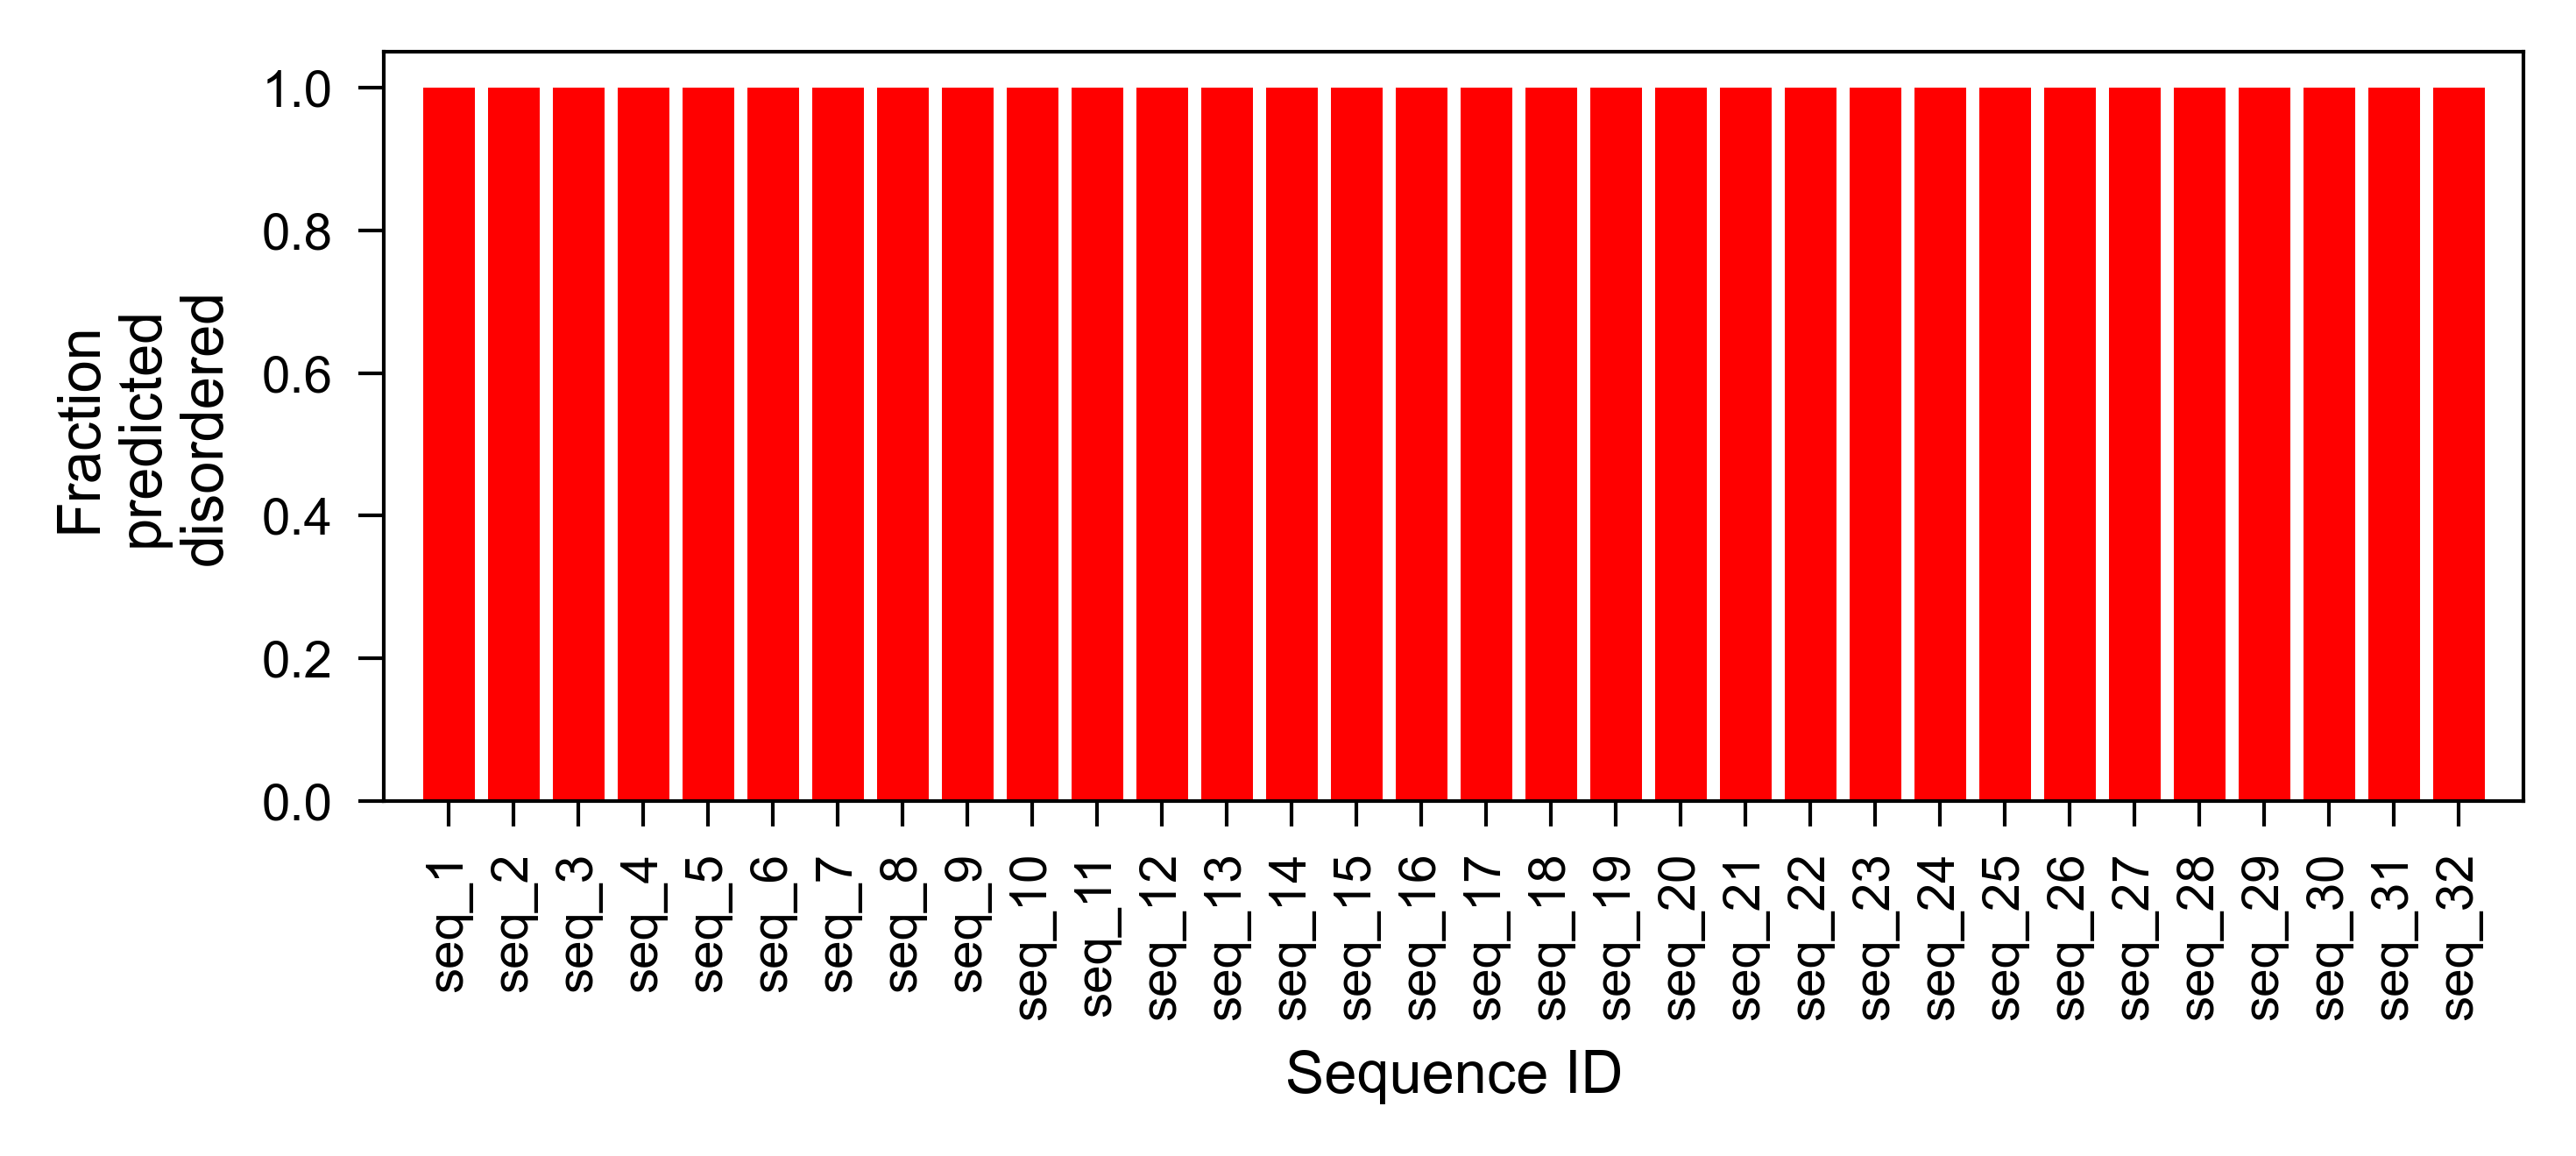

In [2]:
fig, ax = plt.subplots(figsize=(5, 2.3), dpi=300)
ax.bar(np.arange(1, len(disordered) + 1), disordered, color=DISORDERED_COLOR)
ax.set_xticks(np.arange(1, len(disordered) + 1), disordered_names, rotation=90, fontsize=7)
ax.tick_params(axis='y', labelsize=7)
ax.set_xlim([0, len(disordered) + 1])
ax.set_xlabel('Sequence ID', fontsize=8)
ax.set_ylabel('Fraction\npredicted\ndisordered', fontsize=8)
plt.tight_layout()
save_panel(fig, 'figure_S15F')